In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Why the South: governance, firm structure, migration and public spending across regions
Notebook 25 found that Italy's regional slopes are the steepest of 14-18 countries and sit in the South and Islands, but it could not say why. Four candidate explanations are added here, in **two designs side by side** (code: `src/cifresignificative/studies/italy_productivity/analysis/regional_south.py`, `experiments.run_south_all`):
- **Track A, EU-wide** (can be ranked against other countries): the **EQI** (European Quality of Government Index: survey-based perceived quality, impartiality and corruption of public services; waves 2010, 2013, 2017, 2021, 2024; 186 NUTS2 regions, Germany and Belgium are only published at NUTS1 and drop out) and three **structural business statistics** indicators (manufacturing share of business employment, local units per 1,000 inhabitants, wages per person employed; Eurostat, 2008-2020). Regions are demeaned by country, so only differences *within* a country count. Pre-specified family: EQI wave 2017 and its components + the three SBS indicators against six regional gaps (income per head, output per hour, hours per inhabitant, employment rates, unemployment), outcomes averaged over 2015-19; BH control over the family; other waves are replications.
- **Track B, Italy only** (exploratory; there is no placebo country): **internal migration** between regions (Istat registry transfers) and **public spending by region** (Conti Pubblici Territoriali, extended public sector, per inhabitant, by sector and level of government). With 21 regions in one cluster (8 in the South and Islands) the null permutes values across regions, once freely and once **within the three zones** (North, Centre, South and Islands), which asks whether an association survives the North-South split itself.
**Descriptive associations only, never causal**: perceptions of institutions follow prosperity as much as they could precede it, migration follows jobs, and spending is attributed to where it is incurred (pensions and central-government spending included).

In [2]:
from cifresignificative.studies.italy_productivity.analysis import corr, regional_corr as rc, regional_south as rs, experiments as ex
reg, extra = load_regional(), load_regional_extra()
res = ex.run_south_all(reg, extra)
R = rc.regional_matrix(pd.concat([reg, extra], ignore_index=True), drop_flag_chars="u")
e = extra[extra.indicator == "nuts2_eqi"]
print("EQI regions per wave (NUTS2 only):", e.groupby("year").geo.nunique().to_dict(), "| countries:", e.country.nunique(), "| Italian regions per wave:", e[e.geo.str.startswith("IT")].groupby("year").geo.nunique().unique().tolist())
W = rs.within_country(rs.wave_table(R, 2017), income_control=False); g = rc.country_of(W.index)
print("regions with data per indicator in the primary window (2017 wave, outcomes 2015-19):"); display(W[[*rs.EU_WIDE, *rs.OUTCOMES]].notna().sum().to_frame("regions").T)
print("countries with at least 5 regions with data (eligible for Italy's placebo ranking):", int((W[["eqi", "employment_rate_20_64"]].dropna().groupby(g).size() >= 5).sum()))
n = res["s1_null"]
print("\nCalibration of the permutation test: shuffling every column within its country and rerunning the family gives at least one BH discovery in", int((n.discoveries > 0).sum()), "of", len(n), "shuffles; share of tests with p < 0.05:", round(float(n.share_p_below_005.mean()), 3), "(nominal 0.05)")
rng = np.random.default_rng(2); d = W[["eqi", "employment_rate_20_64"]].dropna(); gg = g.reindex(d.index)
hits = [corr._corr(*[corr.shuffle_within(d, gg, rng)[c].to_numpy() for c in d.columns], "spearman")[1] < 0.05 for _ in range(400)]
print("with the ordinary (asymptotic) Spearman p instead, one shuffled test rejects at 5% in", round(float(np.mean(hits)) * 100, 1), "% of 400 shuffles: countries differ in dispersion, which widens the null of the pooled rho; hence permutation p-values below")

EQI regions per wave (NUTS2 only): {2010: 186, 2013: 186, 2017: 186, 2021: 186, 2024: 186} | countries: 20 | Italian regions per wave: [21]
regions with data per indicator in the primary window (2017 wave, outcomes 2015-19):


indicator,eqi,eqi_quality,eqi_impartiality,eqi_corruption,sbs_manufacturing_employment_share_pct,sbs_local_units_per_1000_inhabitants,sbs_wages_per_employee_keur,gdp_pps_pc_eu27,gdp_per_hour_eur,hours_per_inhabitant,employment_rate_20_64,employment_rate_20_64_female,unemployment_rate
regions,182,182,182,182,217,197,211,235,235,235,240,240,239


countries with at least 5 regions with data (eligible for Italy's placebo ranking): 15

Calibration of the permutation test: shuffling every column within its country and rerunning the family gives at least one BH discovery in 2 of 100 shuffles; share of tests with p < 0.05: 0.056 (nominal 0.05)


with the ordinary (asymptotic) Spearman p instead, one shuffled test rejects at 5% in 8.2 % of 400 shuffles: countries differ in dispersion, which widens the null of the pooled rho; hence permutation p-values below


## Track A. EU-wide: within-country associations, primary wave (EQI 2017, outcomes 2015-19)
Pay per employee against income or output per hour is near-definitional and left out of the family (40 pairs remain of 42). The first table is the plain within-country association; the second also removes each region's fit on (country-demeaned) log income per head from every non-income variable, i.e. what is left beyond income.

In [3]:
s1 = res["s1_eu_wide"]
for ic, label in [(False, "plain within-country"), (True, "beyond income")]:
    p = s1[s1.primary & (s1.income_control == ic)]
    print(label, ":", len(p), "tests,", int(p.significant.sum()), "BH discoveries (q <= 0.05); leave-one-country-out sign flips among them:", int(p[p.significant].loo_sign_flips.gt(0).sum()))
tab = s1[s1.primary & ~s1.income_control & s1.x.eq("eqi")].set_index("y").loc[rs.OUTCOMES]
tab2 = s1[s1.primary & s1.income_control & s1.x.eq("eqi")].set_index("y").reindex(rs.OUTCOMES)
display(pd.DataFrame({"n": tab.n, "countries": tab.n_groups, "rho": tab.rho, "q": tab.q_value, "loo min |rho|": tab.loo_min_abs_rho, "rho beyond income": tab2.rho, "q beyond income": tab2.q_value}).round(3))
print("EQI (composite) by wave, rho with each outcome (plain within-country):")
display(s1[~s1.income_control & s1.x.eq("eqi")].pivot(index="y", columns="wave", values="rho").loc[rs.OUTCOMES].round(2))
d = s1[~s1.income_control & s1.primary & s1.significant][["x", "y"]]; m = s1[~s1.income_control].merge(d, on=["x", "y"])
print("the", len(d), "primary discoveries in the other waves: same sign", m.groupby("wave").same_sign_as_primary.mean().round(2).to_dict(), "| q <= 0.05 in the wave", m.groupby("wave").significant.mean().round(2).to_dict())
print("components of the EQI, rho with employment rate 20-64 and unemployment (primary wave, plain):")
display(s1[s1.primary & ~s1.income_control & s1.x.str.startswith("eqi") & s1.y.isin(["employment_rate_20_64", "unemployment_rate"])].pivot(index="x", columns="y", values="rho").round(2))
print("structural business statistics, primary wave: rho plain / beyond income")
a = s1[s1.primary & ~s1.income_control & s1.x.str.startswith("sbs")].set_index(["x", "y"]).rho; b = s1[s1.primary & s1.income_control & s1.x.str.startswith("sbs")].set_index(["x", "y"]).rho
display(pd.DataFrame({"plain": a, "beyond income": b}).unstack("y").round(2))

plain within-country : 40 tests, 37 BH discoveries (q <= 0.05); leave-one-country-out sign flips among them: 0
beyond income : 40 tests, 18 BH discoveries (q <= 0.05); leave-one-country-out sign flips among them: 0


,n,countries,rho,q,loo min |rho|,rho beyond income,q beyond income
y,,,,,,,
gdp_pps_pc_eu27,177,18,0.306,0.001,0.189,0.015,0.894
gdp_per_hour_eur,177,18,0.191,0.016,0.029,-0.067,0.498
hours_per_inhabitant,177,18,0.300,0.001,0.190,0.081,0.380
employment_rate_20_64,181,18,0.364,0.001,0.233,0.446,0.001
employment_rate_20_64_female,181,18,0.356,0.001,0.225,0.444,0.001
unemployment_rate,180,18,-0.406,0.001,0.250,-0.475,0.001


EQI (composite) by wave, rho with each outcome (plain within-country):


wave,2010,2013,2017,2021
y,,,,
gdp_pps_pc_eu27,0.19,0.23,0.31,0.26
gdp_per_hour_eur,0.09,0.09,0.19,0.18
hours_per_inhabitant,0.23,0.30,0.30,0.20
employment_rate_20_64,0.34,0.40,0.36,0.40
employment_rate_20_64_female,0.35,0.38,0.36,0.41
unemployment_rate,-0.36,-0.44,-0.41,-0.45


the 37 primary discoveries in the other waves: same sign {2010: 1.0, 2013: 1.0, 2017: 1.0, 2021: 1.0} | q <= 0.05 in the wave {2010: 0.76, 2013: 0.84, 2017: 1.0, 2021: 0.92}
components of the EQI, rho with employment rate 20-64 and unemployment (primary wave, plain):


y,employment_rate_20_64,unemployment_rate
x,,
eqi,0.36,-0.41
eqi_corruption,0.33,-0.33
eqi_impartiality,0.29,-0.33
eqi_quality,0.36,-0.42


structural business statistics, primary wave: rho plain / beyond income


plain  \
y                                      employment_rate_20_64   
x                                                              
sbs_local_units_per_1000_inhabitants                    0.47   
sbs_manufacturing_employment_share_pct                  0.07   
sbs_wages_per_employee_keur                             0.50   

                                                                     \
y                                      employment_rate_20_64_female   
x                                                                     
sbs_local_units_per_1000_inhabitants                           0.49   
sbs_manufacturing_employment_share_pct                         0.02   
sbs_wages_per_employee_keur                                    0.50   

                                                                         \
y                                      gdp_per_hour_eur gdp_pps_pc_eu27   
x                                                                         
sbs_local_units_per_1000_inhabitants               0.47            0.59   
sbs_manufacturing_employment_share_pct            -0.17           -0.19   
sbs_wages_per_employee_keur                         NaN             NaN   

                                                                               \
y                                      hours_per_inhabitant unemployment_rate   
x                                                                               
sbs_local_units_per_1000_inhabitants                   0.62             -0.39   
sbs_manufacturing_employment_share_pct                -0.20             -0.18   
sbs_wages_per_employee_keur                            0.60             -0.45   

                                               beyond income  \
y                                      employment_rate_20_64   
x                                                              
sbs_local_units_per_1000_inhabitants                   -0.03   
sbs_manufacturing_employment_share_pct                  0.39   
sbs_wages_per_employee_keur                             0.11   

                                                                     \
y                                      employment_rate_20_64_female   
x                                                                     
sbs_local_units_per_1000_inhabitants                          -0.01   
sbs_manufacturing_employment_share_pct                         0.33   
sbs_wages_per_employee_keur                                    0.13   

                                                                         \
y                                      gdp_per_hour_eur gdp_pps_pc_eu27   
x                                                                         
sbs_local_units_per_1000_inhabitants              -0.19           -0.15   
sbs_manufacturing_employment_share_pct             0.05            0.08   
sbs_wages_per_employee_keur                         NaN             NaN   

                                                                               
y                                      hours_per_inhabitant unemployment_rate  
x                                                                              
sbs_local_units_per_1000_inhabitants                   0.32              0.09  
sbs_manufacturing_employment_share_pct                -0.10             -0.47  
sbs_wages_per_employee_keur                           -0.26             -0.08

## Is Italy different? Italy's slope against the other countries' (placebo ranking)
For each pair, the country slope minus the slope of all the other countries is computed for every country with at least 5 regions with data; Italy's rank among them is its p-value, so the smallest possible p is 1 / number of countries (about 0.06).

In [4]:
s2 = res["s2_italy_rank"]
print("countries in the ranking:", int(s2.n_countries.min()), "-", int(s2.n_countries.max()), "| smallest possible p:", round(float((1 / s2.n_countries).min()), 3))
print("pairs where Italy's slope difference is the largest of all countries (p = 1/n):", int((s2.p_diff <= 1 / s2.n_countries + 1e-9).sum()), "of", len(s2))
display(s2.sort_values("p_diff").head(8)[["x", "y", "n_countries", "slope_italy", "slope_others", "p_diff", "slope_north", "slope_south"]].round(3))
print("EQI pairs: Italy's rank p-values", s2[s2.x.str.startswith("eqi")].p_diff.round(2).describe()[["min", "50%", "max"]].to_dict())

countries in the ranking: 14 - 17 | smallest possible p: 0.059
pairs where Italy's slope difference is the largest of all countries (p = 1/n): 6 of 40


,x,y,n_countries,slope_italy,slope_others,p_diff,slope_north,slope_south
34,sbs_local_units_per_1000_inhabitants,employment_rate_20_64_female,17,1.260,0.110,0.059,0.402,1.055
33,sbs_local_units_per_1000_inhabitants,employment_rate_20_64,17,1.042,0.090,0.059,0.291,1.026
28,sbs_manufacturing_employment_share_pct,employment_rate_20_64_female,17,0.680,-0.021,0.059,-0.157,0.538
27,sbs_manufacturing_employment_share_pct,employment_rate_20_64,17,0.638,0.007,0.059,-0.043,0.690
37,sbs_wages_per_employee_keur,employment_rate_20_64,16,2.858,0.805,0.062,0.536,2.977
35,sbs_local_units_per_1000_inhabitants,unemployment_rate,16,-0.501,-0.040,0.062,-0.107,-0.617
38,sbs_wages_per_employee_keur,employment_rate_20_64_female,16,3.349,0.969,0.125,0.199,2.718
26,sbs_manufacturing_employment_share_pct,hours_per_inhabitant,15,4.371,-7.117,0.133,-2.361,6.274


EQI pairs: Italy's rank p-values {'min': 0.43, '50%': 0.64, 'max': 1.0}


## Track B. Italy only (exploratory): internal migration and public spending by region
Window 2015-19, nominal euro, per inhabitant of the year. `rho` = Spearman across the 21 regions; `p_perm` shuffles values across all regions; `rho_within_zone` and `p_perm_within_zone` demean by zone (North 9 regions, Centre 4, South and Islands 8) and shuffle within zones. q is BH over all pairs of Track B: exploratory (one cluster, indicators chosen by eye).

In [5]:
T = res["s_italy_table"].set_index("geo"); s3 = res["s3_italy_only"]
zone = pd.Series({g: rs.zone_of(g) for g in T.index})
print("regions per zone:", zone.value_counts().to_dict(), "| pairs:", len(s3), "| q <= 0.05 unrestricted:", int((s3.q_perm <= 0.05).sum()), "| q <= 0.05 within zones:", int((s3.q_perm_within_zone <= 0.05).sum()))
print("North-South gaps (South and Islands minus North, in standard deviations across the 21 regions):")
gp = res["s5_zone_gaps"].set_index("indicator"); display(gp.loc[[c for c in [*rs.OUTCOMES, *rs.EU_WIDE, "net_migration_per_1000", "outflow_per_1000", "spend_total_pc_eur", "spend_capital_pc_eur", "spend_pensions_pc_eur", "spend_central_level_pc_eur", "spend_regional_level_pc_eur", "spend_local_level_pc_eur", "spend_education_pc_eur", "spend_health_pc_eur"] if c in gp.index]].round(2))
print("migration, per 1,000 inhabitants, 2015-19 averages:"); display(T[["net_migration_per_1000", "inflow_per_1000", "outflow_per_1000", "moves_to_north_per_1000"]].groupby(zone).mean().round(2))
mi = s3[s3.x.isin(["net_migration_per_1000", "inflow_per_1000", "outflow_per_1000", "moves_to_north_per_1000"]) & s3.y.isin(["employment_rate_20_64", "unemployment_rate", "gdp_pps_pc_eu27"])]
display(mi[["x", "y", "rho", "p_perm", "rho_within_zone", "p_perm_within_zone", "loo_min_rho", "loo_max_rho"]].round(3))
sp = s3[(s3.x.str.startswith("spend") | s3.x.eq("capital_share_pct")) & s3.y.isin(["employment_rate_20_64", "gdp_pps_pc_eu27"])]
print("spending (per inhabitant) against employment rate and income per head:")
pv = sp.pivot(index="x", columns="y", values=["rho", "rho_within_zone"]); pv.columns = [f"{a} ({b})" for a, b in pv.columns]
display(pv.join(sp[sp.y == "employment_rate_20_64"].set_index("x")[["p_perm_within_zone"]].rename(columns={"p_perm_within_zone": "p within zones (employment)"})).round(3))
print("pairs surviving within zones (BH q <= 0.05), by x:"); display(s3[s3.q_perm_within_zone <= 0.05].groupby("x").agg(pairs=("y", "size"), rho_within_zone_min=("rho_within_zone", "min"), rho_within_zone_max=("rho_within_zone", "max"), sign_flips=("loo_sign_flips", "max")).round(2))

regions per zone: {'North': 9, 'South and Islands': 8, 'Centre': 4} | pairs: 172 | q <= 0.05 unrestricted: 107 | q <= 0.05 within zones: 16
North-South gaps (South and Islands minus North, in standard deviations across the 21 regions):


,north_mean,south_mean,gap_sd
indicator,,,
gdp_pps_pc_eu27,35273.33,19912.50,-1.90
gdp_per_hour_eur,44.74,33.80,-1.92
hours_per_inhabitant,791.05,590.60,-1.83
employment_rate_20_64,71.76,50.89,-1.93
employment_rate_20_64_female,64.23,38.72,-1.94
unemployment_rate,6.90,16.92,1.85
eqi,-0.52,-1.53,-1.76
eqi_quality,-0.28,-1.51,-1.57
eqi_impartiality,-0.58,-1.27,-1.09


migration, per 1,000 inhabitants, 2015-19 averages:


,net_migration_per_1000,inflow_per_1000,outflow_per_1000,moves_to_north_per_1000
Centre,0.47,6.27,5.80,2.55
North,1.74,7.34,5.60,3.48
South and Islands,-2.74,4.60,7.34,3.75


,x,y,rho,p_perm,rho_within_zone,p_perm_within_zone,loo_min_rho,loo_max_rho
40,net_migration_per_1000,gdp_pps_pc_eu27,0.868,0.000,0.379,0.086,0.847,0.905
43,net_migration_per_1000,employment_rate_20_64,0.897,0.000,0.409,0.104,0.881,0.929
45,net_migration_per_1000,unemployment_rate,-0.912,0.000,-0.431,0.092,-0.928,-0.898
46,inflow_per_1000,gdp_pps_pc_eu27,0.712,0.000,0.231,0.322,0.672,0.767
49,inflow_per_1000,employment_rate_20_64,0.774,0.000,0.497,0.040,0.738,0.820
51,inflow_per_1000,unemployment_rate,-0.705,0.002,-0.344,0.170,-0.789,-0.665
52,outflow_per_1000,gdp_pps_pc_eu27,-0.479,0.026,-0.092,0.695,-0.591,-0.397
55,outflow_per_1000,employment_rate_20_64,-0.512,0.016,0.048,0.860,-0.627,-0.435
57,outflow_per_1000,unemployment_rate,0.561,0.008,0.061,0.812,0.492,0.663
58,moves_to_north_per_1000,gdp_pps_pc_eu27,-0.396,0.079,-0.301,0.208,-0.561,-0.305


spending (per inhabitant) against employment rate and income per head:


,rho (employment_rate_20_64),rho (gdp_pps_pc_eu27),rho_within_zone (employment_rate_20_64),rho_within_zone (gdp_pps_pc_eu27),p within zones (employment)
x,,,,,
capital_share_pct,0.192,0.118,0.599,0.442,0.004
spend_capital_pc_eur,0.532,0.623,0.492,0.583,0.006
spend_central_level_pc_eur,0.673,0.758,0.014,0.140,0.954
spend_education_pc_eur,-0.038,-0.088,0.425,0.416,0.026
spend_environment_pc_eur,0.134,0.130,0.277,0.312,0.205
spend_general_administration_pc_eur,0.519,0.622,0.209,0.510,0.260
spend_health_pc_eur,0.596,0.564,0.448,0.162,0.056
spend_industry_crafts_pc_eur,0.031,0.174,-0.255,-0.006,0.328
spend_justice_pc_eur,-0.840,-0.739,-0.400,-0.240,0.070


pairs surviving within zones (BH q <= 0.05), by x:


,pairs,rho_within_zone_min,rho_within_zone_max,sign_flips
x,,,,
capital_share_pct,3,0.60,0.63,0
eqi,1,-0.61,-0.61,0
eqi_impartiality,4,-0.77,0.84,0
sbs_local_units_per_1000_inhabitants,4,-0.65,0.73,0
spend_capital_pc_eur,1,0.68,0.68,0
spend_local_level_pc_eur,3,0.61,0.68,0


## The two designs side by side
For the indicators that exist EU-wide, Italy's own rho is the same number in both designs (a country-demeaned Spearman within one country is the raw Spearman); what differs is the reference: Track A ranks Italy's slope among other countries, Track B asks whether the 21 regions could produce it by chance, with and without the North-South split held fixed.

In [6]:
s4 = res["s4_compare"]
c = s4[s4.x.isin(["eqi", "eqi_impartiality", "sbs_local_units_per_1000_inhabitants", "sbs_manufacturing_employment_share_pct"]) & s4.y.isin(["employment_rate_20_64", "unemployment_rate", "hours_per_inhabitant"])]
display(c[["x", "y", "n_countries", "slope_italy_A", "slope_others_A", "p_rank_among_countries", "rho_B", "p_perm_B", "rho_within_zone_B", "p_perm_within_zone_B"]].round(3))
print("pairs with an unrestricted Italian permutation p < 0.05:", int((s4.p_perm_B < 0.05).sum()), "| also p < 0.05 within zones:", int(((s4.p_perm_B < 0.05) & (s4.p_perm_within_zone_B < 0.05)).sum()), "| Italy's slope the largest of all countries:", int((s4.p_rank_among_countries <= 1 / s4.n_countries + 1e-9).sum()), "of", len(s4))

,x,y,n_countries,slope_italy_A,slope_others_A,p_rank_among_countries,rho_B,p_perm_B,rho_within_zone_B,p_perm_within_zone_B
2,eqi,hours_per_inhabitant,14,148.770,71.389,0.643,0.807,0.000,0.414,0.076
3,eqi,employment_rate_20_64,15,14.996,7.204,0.667,0.877,0.000,0.553,0.016
5,eqi,unemployment_rate,14,-7.616,-5.621,0.929,-0.894,0.000,-0.606,0.004
14,eqi_impartiality,hours_per_inhabitant,14,120.070,60.216,0.714,0.687,0.001,0.715,0.002
15,eqi_impartiality,employment_rate_20_64,15,11.717,5.511,0.600,0.704,0.000,0.835,0.000
17,eqi_impartiality,unemployment_rate,14,-6.348,-4.299,0.929,-0.716,0.001,-0.774,0.000
26,sbs_manufacturing_employment_share_pct,hours_per_inhabitant,15,4.371,-7.117,0.133,0.292,0.200,-0.042,0.862
27,sbs_manufacturing_employment_share_pct,employment_rate_20_64,17,0.638,0.007,0.059,0.436,0.046,0.283,0.193
29,sbs_manufacturing_employment_share_pct,unemployment_rate,16,-0.352,-0.090,0.312,-0.497,0.026,-0.443,0.031
32,sbs_local_units_per_1000_inhabitants,hours_per_inhabitant,15,10.339,4.751,0.267,0.873,0.000,0.635,0.003


pairs with an unrestricted Italian permutation p < 0.05: 36 | also p < 0.05 within zones: 14 | Italy's slope the largest of all countries: 6 of 40


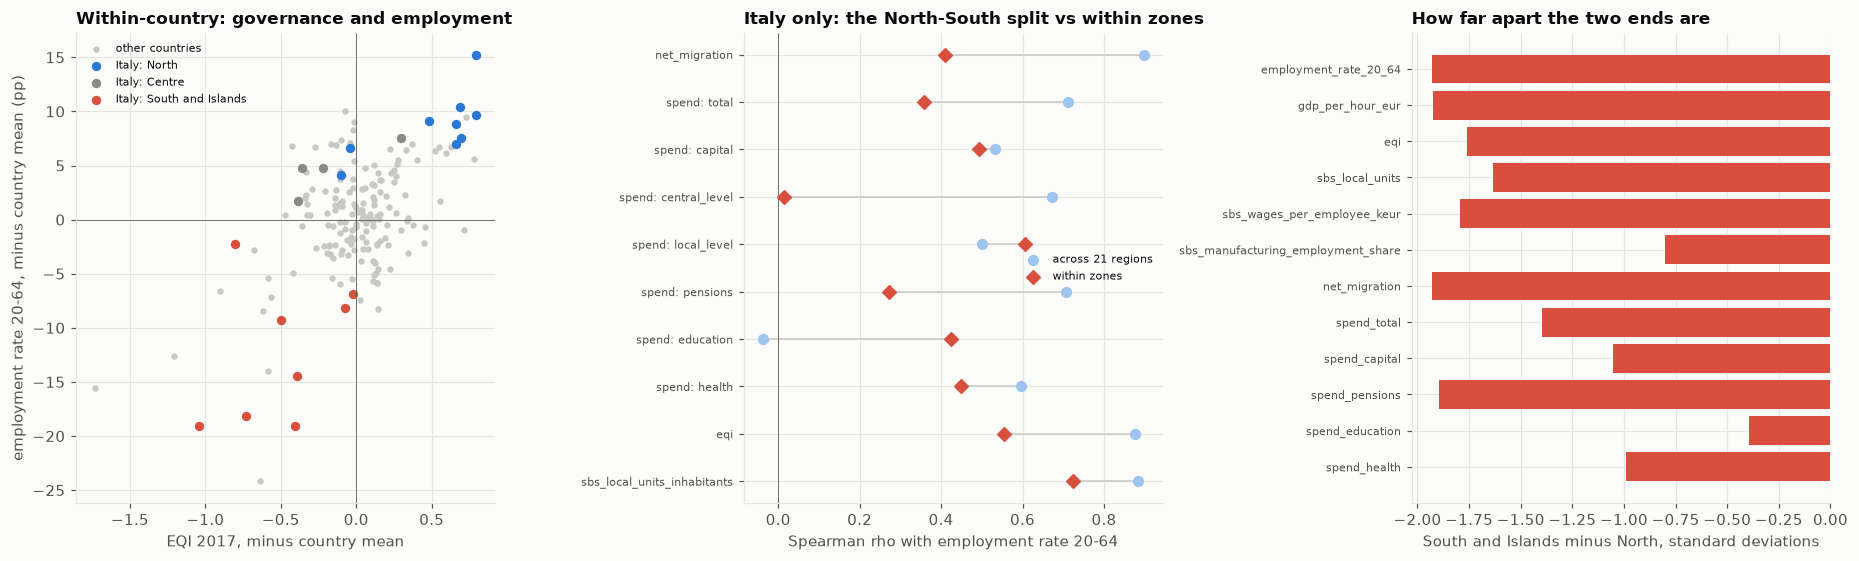

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
ZC = {"North": "#2a78d6", "Centre": "#8a8a85", "South and Islands": "#d94f3d"}
ax = axes[0]; d = W[["eqi", "employment_rate_20_64"]].dropna(); it = d.index.str.startswith("IT")
ax.scatter(d.eqi[~it], d.employment_rate_20_64[~it], s=10, color="#c9c8c3", label="other countries")
for z, col in ZC.items():
    k = d.index.isin([g for g in d.index if g.startswith("IT") and rs.zone_of(g) == z]); ax.scatter(d.eqi[k], d.employment_rate_20_64[k], s=26, color=col, label="Italy: " + z)
ax.axhline(0, color=INK2, lw=0.5); ax.axvline(0, color=INK2, lw=0.5); ax.set_xlabel("EQI 2017, minus country mean"); ax.set_ylabel("employment rate 20-64, minus country mean (pp)"); ax.set_title("Within-country: governance and employment"); ax.legend(fontsize=7)
ax = axes[1]; sel = ["net_migration_per_1000", "spend_total_pc_eur", "spend_capital_pc_eur", "spend_central_level_pc_eur", "spend_local_level_pc_eur", "spend_pensions_pc_eur", "spend_education_pc_eur", "spend_health_pc_eur", "eqi", "sbs_local_units_per_1000_inhabitants"]
q = s3[s3.y.eq("employment_rate_20_64") & s3.x.isin(sel)].set_index("x").loc[sel][::-1]; y = np.arange(len(q))
ax.scatter(q.rho, y, color="#9ec5f0", s=40, label="across 21 regions", zorder=3); ax.scatter(q.rho_within_zone, y, color="#d94f3d", s=40, marker="D", label="within zones", zorder=3)
for yy, a, b in zip(y, q.rho, q.rho_within_zone, strict=True): ax.plot([a, b], [yy, yy], color="#c9c8c3", lw=1)
ax.set_yticks(y, [i.replace("_pc_eur", "").replace("_per_1000", "").replace("spend_", "spend: ")[:30] for i in q.index], fontsize=7.5); ax.axvline(0, color=INK2, lw=0.5); ax.set_xlabel("Spearman rho with employment rate 20-64"); ax.set_title("Italy only: the North-South split vs within zones"); ax.legend(fontsize=7)
ax = axes[2]; gg = gp.loc[[c for c in ["employment_rate_20_64", "gdp_per_hour_eur", "eqi", "sbs_local_units_per_1000_inhabitants", "sbs_wages_per_employee_keur", "sbs_manufacturing_employment_share_pct", "net_migration_per_1000", "spend_total_pc_eur", "spend_capital_pc_eur", "spend_pensions_pc_eur", "spend_education_pc_eur", "spend_health_pc_eur"] if c in gp.index]][::-1]
ax.barh(np.arange(len(gg)), gg.gap_sd, color=["#d94f3d" if v < 0 else "#2a78d6" for v in gg.gap_sd]); ax.set_yticks(np.arange(len(gg)), [i.replace("_pc_eur", "").replace("_per_1000", "").replace("_inhabitants", "")[:34] for i in gg.index], fontsize=7.5); ax.axvline(0, color=INK2, lw=0.5)
ax.set_xlabel("South and Islands minus North, standard deviations"); ax.set_title("How far apart the two ends are")
fig.tight_layout(); save(fig, "34_regional_south")

## Track B, addition: OpenCoesione 2014-2020 by region
`sources/opencoesione.py` reads the five 2014-2020 project files of OpenCoesione (ERDF, ESF, the national Development and Cohesion Fund FSC, the Complementary Action Plan PAC and ordinary resources; 944 thousand projects, 194 billion euro of public financing net of economies allocated to a region; a further 5% has no Italian localisation, and 8% is in projects of several regions and is divided equally among them). Predictors per inhabitant (mean population 2014-2019): the EU part of all funds, the national co-financing of the EU programmes, the FSC, and the share of the financing paid out by mid-2026. **Pre-specified family**: 4 predictors x the 6 outcomes of this notebook (2015-19), Spearman across the 21 regions, permutation p across regions and within the three zones, BH. Since funds are allocated by rule to the poorer regions, the unrestricted column mostly measures the North-South split; the within-zone column is the one to read. A null with the predictors shuffled across regions must give about zero discoveries.


In [8]:
ores = ex.run_opencoesione_all()
oa, oz, of, on, ou = ores["o1_allocation"].set_index("geo"), ores["o2_zones"].set_index("zone"), ores["o3_family"], ores["o4_null"].round(3).to_dict("records")[0], ores["o5_unallocated"]
print("allocation of the 2014-2020 cycle by zone (EUR per inhabitant; payment rate in %):"); display(oz.round(1))
print("what could not be allocated, and multi-region projects, by fund (EUR million):"); display(ou.round(0))
print("family:", len(of), "tests | BH discoveries unrestricted:", int((of.q_perm <= 0.05).sum()), "| within zones:", int((of.q_perm_within_zone <= 0.05).sum()), "| leave-one-out sign flips among the unrestricted discoveries:", int(of[of.q_perm <= 0.05].loo_sign_flips.gt(0).sum()))
print("null (predictors shuffled across regions):", on)
display(of.pivot(index="x", columns="y", values="rho").round(2)); print("within zones:"); display(of.pivot(index="x", columns="y", values="rho_within_zone").round(2)); print("within-zone permutation p, smallest three:"); display(of.sort_values("p_perm_within_zone").head(3)[["x", "y", "rho_within_zone", "p_perm_within_zone", "q_perm_within_zone"]].round(3))
print("regions with the most and the least EU funds per inhabitant:"); display(oa.sort_values("oc_eu_pc_eur").iloc[[0, 1, 2, -3, -2, -1]].round(1))


allocation of the 2014-2020 cycle by zone (EUR per inhabitant; payment rate in %):


,oc_eu_pc_eur,oc_cofin_pc_eur,oc_fsc_pc_eur,oc_payment_rate_pct
zone,,,,
North,484.6,264.5,839.0,82.4
Centre,490.7,270.4,910.9,76.9
South and Islands,2307.3,892.7,4938.5,61.7
South / North,4.8,3.4,5.9,0.7


what could not be allocated, and multi-region projects, by fund (EUR million):


,fund,projects,projects_unallocated,total_public_meur,unallocated_total_public_meur,multi_area_projects,multi_area_total_public_meur
0,FESR,154991,178,53847.0,1863.0,638,8908.0
1,FSE,431459,727,25859.0,3912.0,360,7085.0
2,FSC,122174,1150,112556.0,3700.0,182,872.0
3,PAC,134866,100,11854.0,1053.0,87,175.0
4,ORD,100738,2,607.0,11.0,13,2.0


family: 24 tests | BH discoveries unrestricted: 24 | within zones: 0 | leave-one-out sign flips among the unrestricted discoveries: 0
null (predictors shuffled across regions): {'n_shuffle': 100, 'share_any_discovery': 0.04, 'mean_discoveries': 0.53, 'share_any_discovery_within_zone': 0.06, 'mean_discoveries_within_zone': 0.29}


y,employment_rate_20_64,employment_rate_20_64_female,gdp_per_hour_eur,gdp_pps_pc_eu27,hours_per_inhabitant,unemployment_rate
x,,,,,,
oc_cofin_pc_eur,-0.77,-0.72,-0.73,-0.76,-0.75,0.80
oc_eu_pc_eur,-0.74,-0.69,-0.76,-0.76,-0.73,0.80
oc_fsc_pc_eur,-0.73,-0.68,-0.73,-0.74,-0.74,0.78
oc_payment_rate_pct,0.74,0.71,0.62,0.66,0.66,-0.78


... (2 outputs left out)

within-zone permutation p, smallest three:


,x,y,rho_within_zone,p_perm_within_zone,q_perm_within_zone
23,oc_payment_rate_pct,unemployment_rate,-0.427,0.063,0.722
21,oc_payment_rate_pct,employment_rate_20_64,0.388,0.082,0.722
19,oc_payment_rate_pct,gdp_per_hour_eur,-0.387,0.124,0.722


regions with the most and the least EU funds per inhabitant:


,oc_eu_pc_eur,oc_cofin_pc_eur,oc_fsc_pc_eur,oc_payment_rate_pct
geo,,,,
ITC4,175.5,107.3,341.7,77.9
ITH2,179.1,187.3,328.2,87.5
ITH1,230.8,246.6,1322.8,74.8
ITF6,2542.5,708.5,5394.4,61.4
ITF2,3972.5,383.7,9860.6,68.4
ITF5,4158.8,1819.2,5983.0,67.9


## Takeaways (EQI 2010-2024, Eurostat structural business statistics 2008-2020, Istat internal migration, CPT spending; primary window 2015-19; descriptive associations)
- **The permutation test was needed.** The ordinary Spearman p-value rejects a *shuffled* within-country test 8.2% of the time at the nominal 5% (400 shuffles), because countries differ in dispersion. All EU-wide p-values here are within-country permutation p-values (2,000 shuffles, so the smallest p is 0.0005); shuffling every column within its country and rerunning the family gives a BH discovery in 2 of 100 shuffles and p < 0.05 in 5.6% of tests. (The earlier regional screen, notebook 25, uses the asymptotic p with robustness filters; this check was not repeated there.)
- **Track A. Within a country, regions with better perceived governance have more people at work, beyond what income explains.** EQI (2017) against the employment rate 20-64: rho 0.36 across 181 regions in 18 countries; against unemployment -0.41; income per head 0.31; hours worked per inhabitant 0.30; output per hour only 0.19 (q 0.016, and its leave-one-country-out minimum is 0.03). Employment and unemployment hold in all four waves (employment rho 0.34, 0.40, 0.36, 0.40 for 2010-2021; unemployment -0.36 to -0.45). Of 40 pairs, 37 pass BH at 5% in the primary wave, none flips sign when a country is dropped, and the 37 keep their sign in every other wave (q <= 0.05 in 76%, 84% and 92% of them in 2010, 2013 and 2021). After removing each region's fit on income per head, 18 of 40 survive: EQI keeps employment (0.45), female employment (0.44) and unemployment (-0.475, all q 0.001) but its link with income per head (0.02), output per hour (-0.07) and hours per inhabitant (0.08) disappears. All three components point the same way; quality is the strongest (employment 0.36, unemployment -0.42), then corruption (0.33) and impartiality (0.29).
- **Firm structure mostly tracks income.** Local units per 1,000 inhabitants goes with employment (0.47), hours per inhabitant (0.62) and income per head (0.59), but beyond income the link is about zero (employment -0.03). Manufacturing's share of business employment is weakly linked to employment at first (0.07) and to output per hour negatively (-0.17), but beyond income it goes with higher employment (0.39) and lower unemployment (-0.47). Pay per person employed goes with employment (0.50) and unemployment (-0.45) but is near zero beyond income (employment 0.11); pay against income or output per hour is near-definitional and not tested.
- **Italy against the other countries (placebo ranking, 14-17 countries).** In 6 of 40 pairs Italy's slope difference is the largest of all countries, the smallest p the ranking can give (1/n, 0.059 to 0.071, so no pair can reach 0.05): the six are local units per 1,000 inhabitants (employment, female employment, unemployment), the manufacturing share (employment, female employment) and pay per person employed (employment). Example: one more local unit per 1,000 inhabitants goes with 1.04 pp more employment in Italy's regions (1.03 in the South, 0.29 in the North) against 0.09 pp in the other countries. For the EQI Italy is not unusual: its rank p-values are 0.43 to 1.00 (median 0.64), so the governance-employment link looks like the other countries' link, only on a larger spread.
- **Track B. Migration is the North-South split.** South and Islands lose 2.7 residents per 1,000 a year net to other regions (North +1.7): inflow 4.6 against 7.3, outflow 7.3 against 5.6. Across the 21 regions net migration goes with the employment rate (rho 0.90, p < 0.001), income per head (0.87) and unemployment (-0.91), but within the three zones it falls to 0.41 (p 0.10), 0.38 (0.09) and -0.43 (0.09): none of the migration pairs survives BH within zones. Moves to the North per 1,000 inhabitants are weakly related to the labour market within zones (employment -0.46, p 0.052; unemployment 0.48, p 0.040; not BH-significant). Migration follows jobs as much as it could cause the gap.
- **Track B. Spending: the central part follows the split, the capital and local part survives it.** Total spending per inhabitant is 20.2 thousand EUR in the North and 14.9 in the South and Islands (gap 1.4 SD); it goes with income per head (rho 0.82) and employment (0.71), and within zones with income (0.61, p 0.01) and employment (0.36, p 0.07). Central-government spending per inhabitant (rho 0.67 with employment) falls to 0.01 within zones (p 0.95) and pensions (0.71) to 0.28 (p 0.25): they sit where the older, richer population is. Capital spending per inhabitant keeps its association within zones (0.53 across regions, 0.49 within, p 0.01), as does spending by local governments (0.49 and 0.61, p < 0.01); the capital share of spending goes from 0.20 to 0.60 within zones (p < 0.01), and education spending from -0.04 to 0.41 (p 0.03).
- **The designs side by side.** 36 of the 40 EU-wide pairs have an Italian permutation p < 0.05 across the 21 regions and 14 also within zones, among them all four pairs each of EQI impartiality and of local units per 1,000 inhabitants (p <= 0.003 within zones) and the EQI composite with unemployment (-0.61, p 0.004). The manufacturing share does not survive the zone split for employment (p 0.19) and hours (p 0.86), with unemployment the exception (p 0.031), consistent with a link that is mostly the North-South difference. Track A alone cannot say this (it ranks Italy among countries), and Track B alone cannot say that Italy's local-unit slope is unusual; the two together single out firm structure for Italy and show governance as a within-country regularity that Italy shares. Track B BH q-values cover 172 pairs chosen by eye: 16 survive within zones (6 indicators: EQI, impartiality, local units, capital share, capital spending, local-government spending).
- **OpenCoesione 2014-2020: the funds follow the North-South split and nothing remains within zones.** South and Islands received 2,307 euro of EU funds per inhabitant against 485 in the North (4.8 times), 893 against 264 of national co-financing of the EU programmes (3.4 times) and 4,939 against 839 of the FSC (5.9 times), while the share paid out is 62% against 82%. Across the 21 regions all four predictors are strongly associated with every outcome (rho -0.68 to -0.77 with income, employment and hours, +0.78 to +0.80 with unemployment for the funds; the payment rate +0.62 to +0.74), and all 24 pairs are BH discoveries, but within zones none is (smallest within-zone p 0.063, rho -0.43 for the payment rate against unemployment; 0 of 24 at q <= 0.05) and the shuffled-predictor null gives a discovery in 4% of 100 shuffles in the unrestricted column (mean 0.53 discoveries) and 6% within zones (mean 0.29). So the data do not separate the allocation rule (funds go where income is low) from any effect of the funds; Sicily's low payment rate (38%) is visible but does not carry a within-zone pattern. Projects of several regions are split equally and 5% of the money has no Italian localisation. Descriptive.
- **Limits.** EQI measures perceptions from surveys with margins of error, 2010-2024, Germany and Belgium are missing (NUTS1); a perception of institutions can follow prosperity as well as precede it. Structural business statistics end in 2020, persons employed include the self-employed (so pay per person is not pay per employee), and local units include one-person units. Spending is attributed to where it is incurred and includes central-government spending and pensions (28% of the total on average), so it is not what regional governments choose. Migration is registry transfers, with age only as a total (no education of movers). With 21 regions, 8 in the South and Islands and three zones, Track B has little power and its p-values are exploratory; the zone split removes real North-South differences as well as confounding. Nothing here separates cause from consequence: no claim that better institutions, firm structure, migration or spending cause the South's gap or close it.
